<h1>Muhammad Abdullah</h1>
<h4>F22607010</h4>

### TASK 1: Using Euclidean Distance ###

Method: Single Linkage (Euclidean Distance)


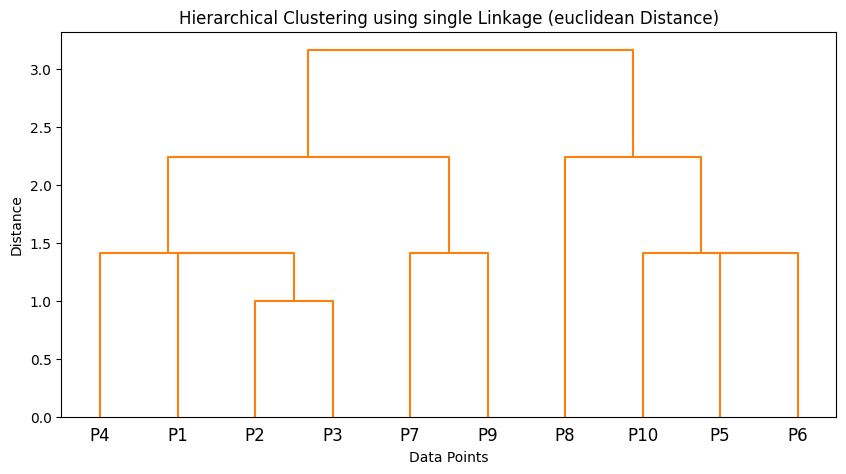


Method: Complete Linkage (Euclidean Distance)


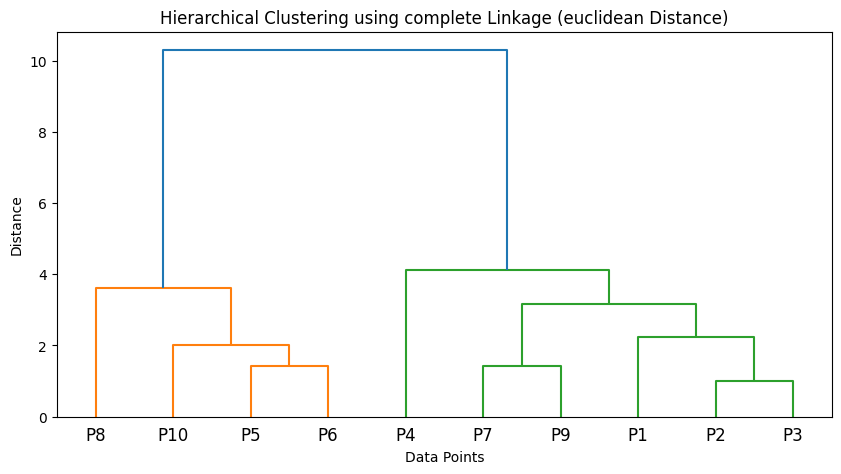


Method: Average Linkage (Euclidean Distance)


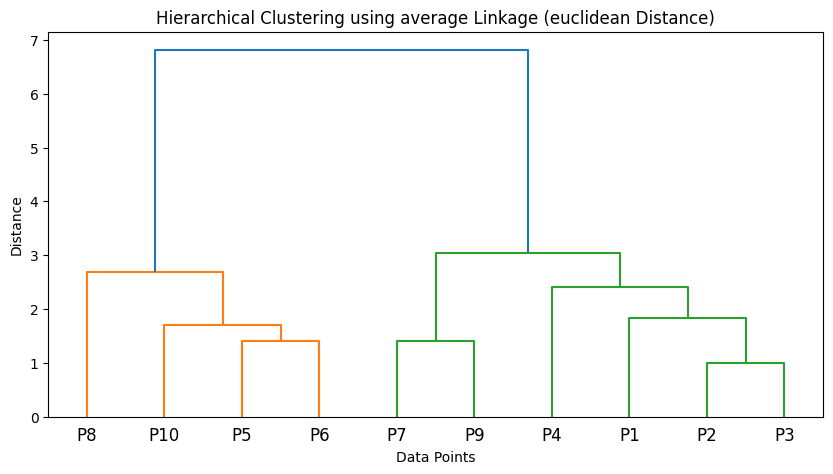


Method: Centroid Linkage (Euclidean Distance)


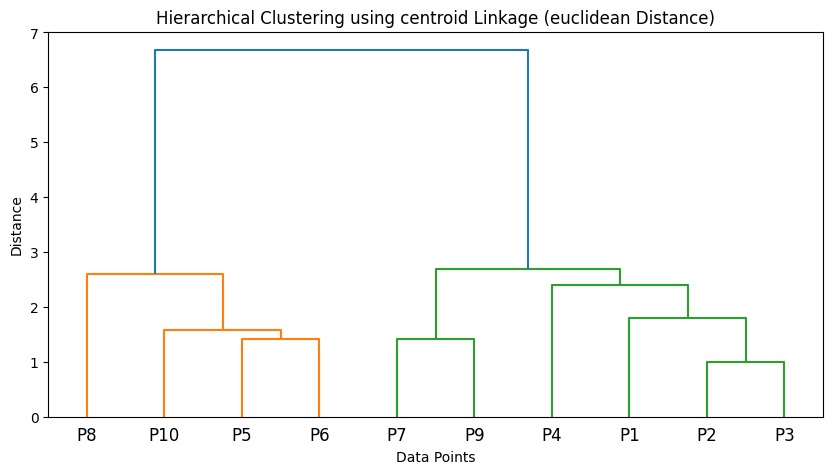


### TASK 2: Using Manhattan Distance ###

Method: Single Linkage (Cityblock Distance)


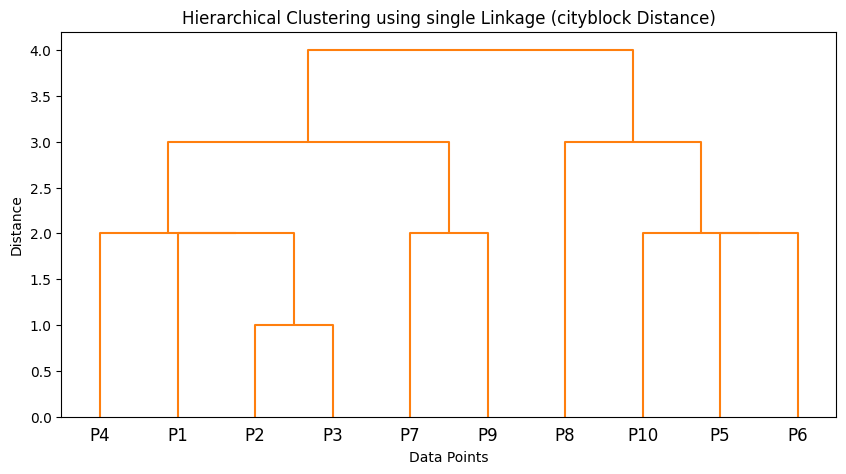


Method: Complete Linkage (Cityblock Distance)


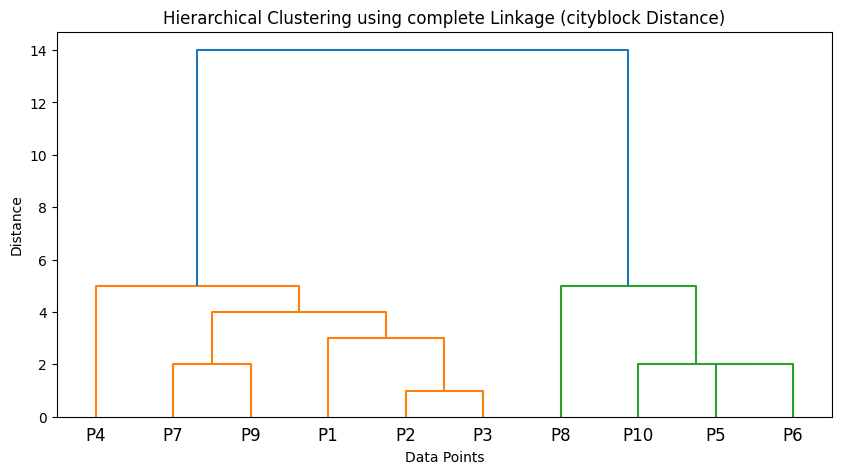


Method: Average Linkage (Cityblock Distance)


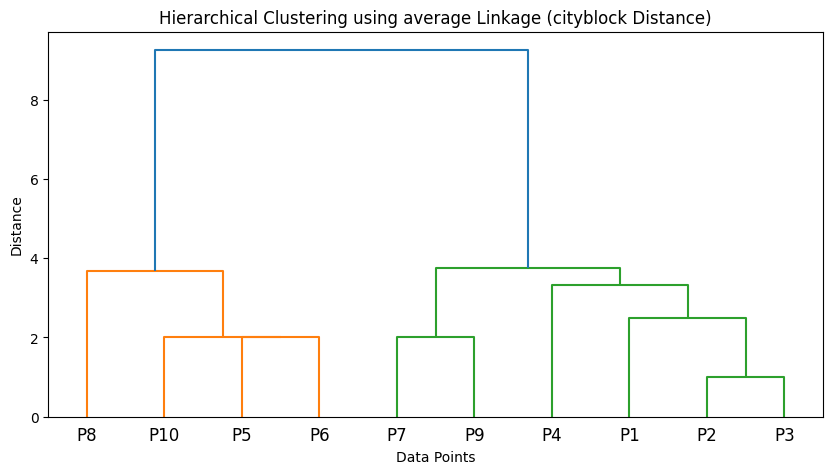


### Cutting Dendrogram for Desired Clusters ###
Clusters (Method: single, Metric: euclidean): [1 1 1 1 2 2 1 2 1 2]


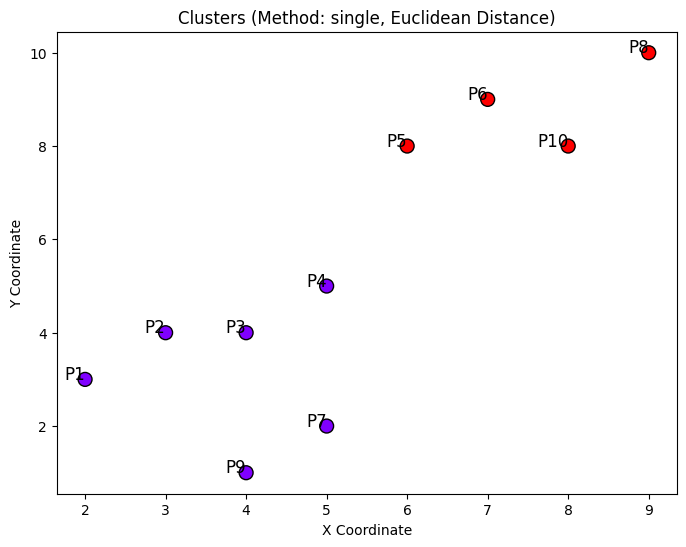

Clusters (Method: complete, Metric: cityblock): [1 1 1 1 2 2 1 2 1 2]


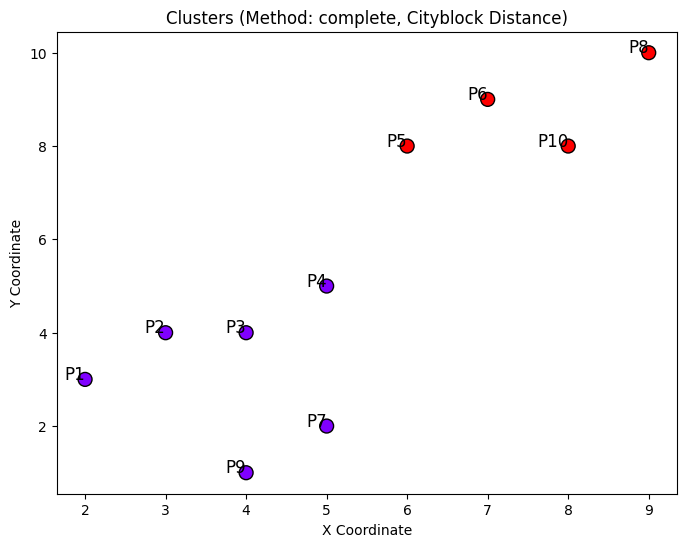

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist, squareform

# 1. DATASET CREATION
# Synthetic dataset with coordinates
data = np.array([
    [2, 3], [3, 4], [4, 4], [5, 5],
    [6, 8], [7, 9], [5, 2], [9, 10],
    [4, 1], [8, 8]
])

labels = [f'P{i}' for i in range(1, len(data) + 1)]  

# Function to plot the dendrogram
def plot_dendrogram(linkage_matrix, method, metric):
    plt.figure(figsize=(10, 5))
    dendrogram(linkage_matrix, labels=labels, color_threshold=6)
    plt.title(f'Hierarchical Clustering using {method} Linkage ({metric} Distance)')
    plt.xlabel('Data Points')
    plt.ylabel('Distance')
    plt.show()

# Function to apply clustering and plot dendrogram
def hierarchical_clustering(data, metric='euclidean'):
    methods = ['single', 'complete', 'average']
    
    if metric == 'euclidean': 
        methods.append('centroid')
    
    for method in methods:
        print(f"\nMethod: {method.capitalize()} Linkage ({metric.capitalize()} Distance)")
        # linkage
        linkage_matrix = linkage(data, method=method, metric=metric)
        #  dendrogram
        plot_dendrogram(linkage_matrix, method=method, metric=metric)


# 2. TASK 1: EUCLIDEAN DISTANCE
print("### TASK 1: Using Euclidean Distance ###")
hierarchical_clustering(data, metric='euclidean')

# 3. TASK 2: MANHATTAN DISTANCE
print("\n### TASK 2: Using Manhattan Distance ###")
hierarchical_clustering(data, metric='cityblock')

# 4. CUTTING DENDROGRAM FOR DESIRED CLUSTERS
def cut_dendrogram(data, method, metric, num_clusters=3):
    linkage_matrix = linkage(data, method=method, metric=metric)
    clusters = fcluster(linkage_matrix, num_clusters, criterion='maxclust')
    print(f"Clusters (Method: {method}, Metric: {metric}): {clusters}")
    
    # Plot clusters
    plt.figure(figsize=(8, 6))
    plt.scatter(data[:, 0], data[:, 1], c=clusters, cmap='rainbow', edgecolors='k', s=100)
    for i, label in enumerate(labels):
        plt.text(data[i, 0], data[i, 1], label, fontsize=12, ha='right')
    plt.title(f'Clusters (Method: {method}, {metric.capitalize()} Distance)')
    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.show()

# Cutting Dendrogram for Single Linkage (Euclidean)
print("\n### Cutting Dendrogram for Desired Clusters ###")
cut_dendrogram(data, method='single', metric='euclidean', num_clusters=3)
cut_dendrogram(data, method='complete', metric='cityblock', num_clusters=3)
